# Intro to Data Visualization (Fall 2026) - Assignment 2

**Ivy League Graduate Earnings and Rising Global Temperatures**

Group members: Amar Preet Singh, Samridh Barthaval, Prakash Periyasamy

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Question 1 - Box Plots - Ranking the Ivies

We only have the percentiles for each school (10th, 25th, median, 75th, 90th), not the raw earnings,
so `sns.boxplot` can't compute the boxes for us. Instead we pass the numbers straight to matplotlib's
`bxp()`, which draws a box plot from pre-computed statistics. Seaborn is used for the colours and for
removing the frame.

In [ ]:
earnings = pd.read_csv('college-earnings.csv')

ivy_names = {
    'Harvard University': 'Harvard',
    'University of Pennsylvania': 'UPenn',
    'Princeton University': 'Princeton',
    'Columbia University in the City of New York': 'Columbia',
    'Cornell University': 'Cornell',
    'Dartmouth College': 'Dartmouth',
    'Yale University': 'Yale',
    'Brown University': 'Brown',
}

ivies = earnings[earnings['INSTNM'].isin(ivy_names.keys())].copy()
ivies['school'] = ivies['INSTNM'].map(ivy_names)

ivies['PCT10_EARN_WNE_P10'] = pd.to_numeric(ivies['PCT10_EARN_WNE_P10'], errors='coerce')
ivies['PCT90_EARN_WNE_P10'] = pd.to_numeric(ivies['PCT90_EARN_WNE_P10'], errors='coerce')

ivies = ivies.rename(columns={
    'PCT10_EARN_WNE_P10': 'p10',
    'PCT25_EARN_WNE_P10': 'p25',
    'MD_EARN_WNE_P10': 'median',
    'PCT75_EARN_WNE_P10': 'p75',
    'PCT90_EARN_WNE_P10': 'p90',
})
ivies = ivies[['school', 'p10', 'p25', 'median', 'p75', 'p90']]

ivies = ivies.sort_values('median', ascending=False).reset_index(drop=True)
ivies

,school,p10,p25,median,p75,p90
0,UPenn,22700,69735.0,111371.0,183142.0,236200
1,Princeton,20800,68313.0,110066.0,197494.0,217200
2,Cornell,23100,67090.0,104043.0,166446.0,178800
3,Columbia,16600,62687.0,102491.0,162279.0,205500
4,Harvard,24700,65309.0,101817.0,200054.0,250000
5,Yale,15400,66022.0,100533.0,193688.0,184800
6,Dartmouth,16900,64562.0,97434.0,189467.0,210500
7,Brown,17200,63520.0,93487.0,164436.0,161000


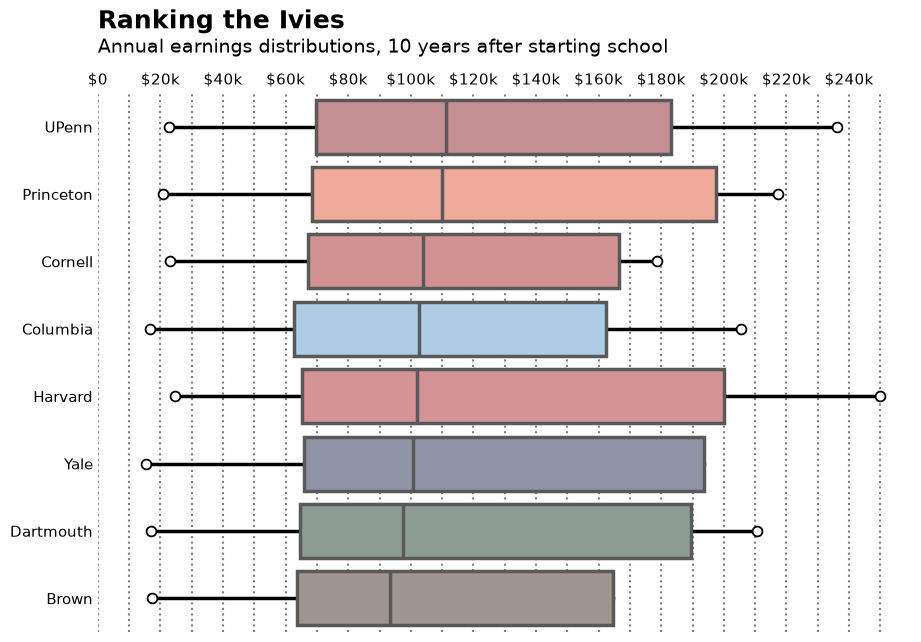

In [ ]:
colours = {
    'Harvard': '#E1888B',
    'UPenn': '#CD868A',
    'Princeton': '#FFA18A',
    'Columbia': '#A5CEEE',
    'Cornell': '#DD8786',
    'Dartmouth': '#899F96',
    'Yale': '#8B90AA',
    'Brown': '#9F958F',
}

box_stats = []
for _, row in ivies.iterrows():
    box_stats.append({
        'label': row['school'],
        'whislo': row['p10'],
        'q1': row['p25'],
        'med': row['median'],
        'q3': row['p75'],
        'whishi': row['p90'],
        'fliers': [],
    })

# bxp draws position 1 at the bottom, so count down to keep the top school on top
positions = list(range(len(ivies), 0, -1))

fig, ax = plt.subplots(figsize=(10.5, 7))

boxes = ax.bxp(box_stats, positions=positions, orientation='horizontal',
               widths=0.8, patch_artist=True, showcaps=False,
               boxprops=dict(edgecolor='#595959', linewidth=2.5, zorder=3),
               medianprops=dict(color='#595959', linewidth=2.5, zorder=4),
               whiskerprops=dict(color='black', linewidth=2.5, zorder=1))

for patch, school in zip(boxes['boxes'], ivies['school']):
    patch.set_facecolor(sns.desaturate(colours[school], 0.75))

# empty circles at the end of each whisker (10th and 90th percentile)
ax.scatter(ivies['p10'], positions, s=50, facecolor='white', edgecolor='black',
           linewidth=1.3, zorder=2, clip_on=False)
ax.scatter(ivies['p90'], positions, s=50, facecolor='white', edgecolor='black',
           linewidth=1.3, zorder=2, clip_on=False)

# x axis on top
ax.xaxis.tick_top()
ax.set_xlim(0, 260000)
ax.set_xticks(range(0, 240001, 20000))
ax.set_xticklabels(['$0'] + [f'${x // 1000}k' for x in range(20000, 240001, 20000)])
ax.set_xticks(range(0, 250001, 10000), minor=True)
ax.grid(axis='x', which='both', color='grey', linestyle=':', linewidth=1.5)
ax.set_axisbelow(True)
ax.tick_params(axis='both', which='both', length=0, labelsize=11)

sns.despine(left=True, bottom=True)

# title + subtitle, left aligned with the plot
ax.text(0, 1.12, 'Ranking the Ivies', transform=ax.transAxes,
        fontsize=18, fontweight='bold')
ax.text(0, 1.075, 'Annual earnings distributions, 10 years after starting school',
        transform=ax.transAxes, fontsize=14)

plt.show()

Note: for Yale and Brown the 90th percentile in the data is actually lower than the 75th percentile
(Yale: 184,800 vs 193,688, Brown: 161,000 vs 164,436). Because the whiskers and circles are drawn
underneath the boxes, their right whisker ends up hidden inside the box, which is also how it looks
in the reference image.

## Question 2 - Histograms - The Average Global Temperature Keeps Climbing

The data has one row per year and one column per month, so we melt it into one column of monthly
deviations and give every value a decade. Each decade (1880s to 2010s) then gets its own histogram,
drawn on the same axes from oldest to newest. The colour of each histogram comes from the `coolwarm`
palette, based on where that decade's mean deviation sits between the coldest and the warmest decade.

In [7]:
temps = pd.read_csv('temps.csv')

# wide -> long: one row per (year, month) so each value is one monthly deviation
temps_long = temps.melt(id_vars='Year', var_name='Month', value_name='deviation')
temps_long['decade'] = (temps_long['Year'] // 10) * 10

# quick check: the deviations are measured from the 1951-1980 average,
# so that period should average out to about 0
baseline = temps_long[temps_long['Year'].between(1951, 1980)]
print('1951-1980 mean deviation:', round(baseline['deviation'].mean(), 4))

decade_means = temps_long.groupby('decade')['deviation'].mean()
decade_means

1951-1980 mean deviation: -0.0002


decade
1880   -0.202083
1890   -0.231333
1900   -0.307917
1910   -0.320500
1920   -0.235917
1930   -0.117667
1940    0.047167
1950   -0.046917
1960   -0.029833
1970    0.033583
1980    0.245000
1990    0.383417
2000    0.586417
2010    0.805833
Name: deviation, dtype: float64

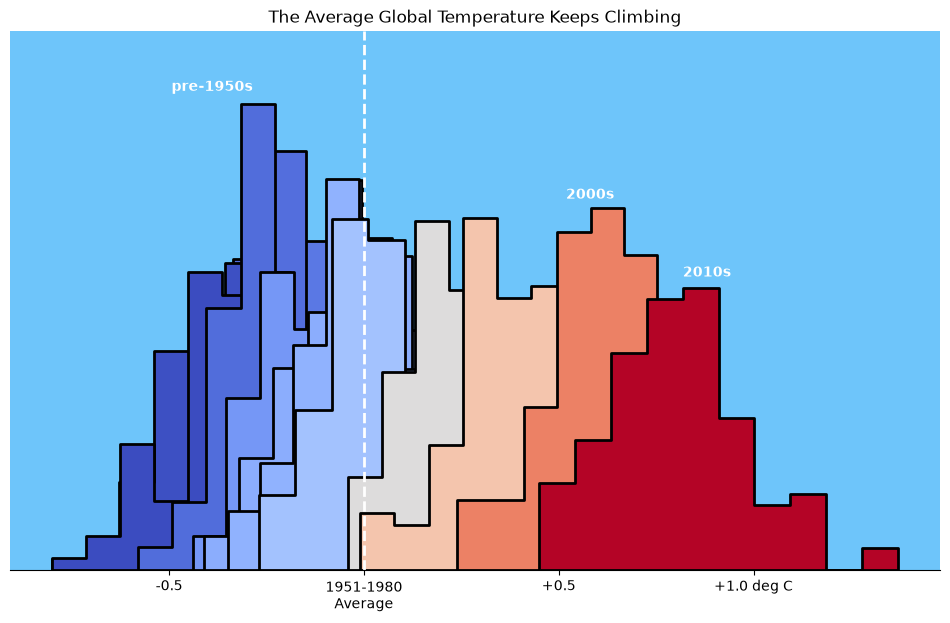

In [ ]:
# colour of each decade = its mean deviation placed on the coolwarm scale
coolwarm = sns.color_palette('coolwarm', as_cmap=True)
lo = decade_means.min()
hi = decade_means.max()

fig, ax = plt.subplots(figsize=(12, 7))

bin_width = 0.09  # each bin is ~0.09 deg C wide (counted the bins in the reference)

for decade, group in temps_long.groupby('decade'):
    values = group['deviation']
    n_bins = int(round((values.max() - values.min()) / bin_width))
    colour = coolwarm((decade_means[decade] - lo) / (hi - lo))

    sns.histplot(values, bins=n_bins, stat='density', element='step',
                 color=colour, alpha=1, edgecolor='black', linewidth=2, ax=ax)

# 1951-1980 average is 0 in this data (the deviations are measured from it)
ax.axvline(0, color='white', linestyle='--', linewidth=2)

ax.text(-0.39, 4.0, 'pre-1950s', color='white', fontweight='bold', ha='center')
ax.text(0.58, 3.1, '2000s', color='white', fontweight='bold', ha='center')
ax.text(0.88, 2.45, '2010s', color='white', fontweight='bold', ha='center')

ax.set_facecolor('#6EC5FA')
ax.set_ylim(0, 4.5) 
ax.set_xticks([-0.5, 0, 0.5, 1.0])
ax.set_xticklabels(['-0.5', '1951-1980\nAverage', '+0.5', '+1.0 deg C'])
ax.set_yticks([])
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('The Average Global Temperature Keeps Climbing')

for side in ['left', 'right', 'top']:
    ax.spines[side].set_visible(False)

plt.show()

## Attribution

This assignment was completed by Group 9: Samridh, Amar, and Prakash. We referred to the Matplotlib and Seaborn documentation for plotting syntax and the pandas documentation for working with DataFrames. We also used AI tools to help troubleshoot and debug issues in our code.